# Robust RFF Ridge Regression — Experiments from `project/desc.tex`

This notebook implements the tests described in the project prospectus
(`project/desc.tex`). Sections map onto the prospectus as follows:

| Section | Prospectus reference |
|---|---|
| 1. Sanity checks | Milestone 1 — resolvent identity (eq. resolvent), truncation bound (eq. trunc-bound), 2-D whitening example |
| 2. Clean RFF baseline | Milestone 2 — exact KRR vs. RFF ridge as $m$ and $\lambda$ vary |
| 3. Synthetic diagonal design | §Experiments + Milestone 3 — prescribed diagonal $M$, controlled target placement, pair contamination; sweeps over $\epsilon, n, \lambda, \tau$; $\|\widehat M-M\|_{op}$, $\Delta_\lambda$, energy below $\tau$; low-variance adversary |
| 4. Full RFF pipeline | §Experiments + §From finite-dim back to KRR — robust RFF vs. nonrobust RFF, oracle clean RFF, exact clean KRR; error decomposition (eq. decomp) |

**Conventions** (following the prospectus):
* $Z=\Phi(X)$, $M=\mathbb E[ZZ^\top]$ (second moment, *not* covariance), $c=\mathbb E[ZY]$.
* Population ridge target $\beta_\lambda=(M+\lambda I)^{-1}c$; primary comparator is $\beta_\lambda$.
* Prediction error of a coefficient error $h$ is $\|M^{1/2}h\|_2=\|h^\top\Phi\|_{L^2(P_X)}$.
* Contamination is **strong replacement of complete pairs** $(z,y)$ in feature space: the adversary sees
  the clean sample *and* the realized feature map, and need not submit vectors consistent with $\Phi(x)$.
* Responses are bounded (first-theorem setting): $|Y|\le B_y$.

In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.kernel_ridge import KernelRidge

SEED = 0
rng = np.random.default_rng(SEED)

# Fixed estimator -> color map (color follows the estimator, never its rank)
COLORS = {
    "oracle clean":    "#2a78d6",
    "nonrobust":       "#eb6834",
    "bound filter":    "#1baf7a",
    "GMoM ridge":      "#eda100",
    "robust whitening": "#e87ba4",
    "robust truncated": "#008300",
    "exact clean KRR": "#4a3aa7",
    "population":      "#e34948",
}
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "lines.markersize": 6, "legend.frameon": False,
})

## 0. Building blocks

### Random Fourier features (eq. rff)
For the Gaussian kernel $k_\sigma(x,x')=\exp(-\|x-x'\|^2/2\sigma^2)$, $\omega_j\sim\mathcal N(0,\sigma^{-2}I_d)$,
$b_j\sim\mathrm{Unif}[0,2\pi]$ and $\Phi(x)=\sqrt{2/m}\,(\cos(\omega_j^\top x+b_j))_{j}$, so $\|\Phi(x)\|_2^2\le 2$.

In [2]:
def sample_rff(d, m, sigma, rng):
    """Draw the random feature map parameters (omega_j, b_j) for the Gaussian kernel of width sigma."""
    W = rng.normal(0.0, 1.0 / sigma, size=(m, d))
    b = rng.uniform(0.0, 2 * np.pi, size=m)
    return W, b


def rff(X, W, b):
    """Phi(x) = sqrt(2/m) cos(W x + b), one row per point."""
    return np.sqrt(2.0 / W.shape[0]) * np.cos(X @ W.T + b)


def gaussian_kernel(X1, X2, sigma):
    sq = np.sum(X1**2, 1)[:, None] - 2 * X1 @ X2.T + np.sum(X2**2, 1)[None, :]
    return np.exp(-np.maximum(sq, 0) / (2 * sigma**2))

### Moment estimators

* **empirical** — $\widehat M=\frac1n\sum z_iz_i^\top$, $\widehat c=\frac1n\sum z_iy_i$ (nonrobust; also the *oracle* when fed the clean sample).
* **bound filter** — reject pairs with $\|z\|_2>B_z$ or $|y|>B_y$ (clean data satisfy both deterministically), then empirical moments.
  This is route (c): the surviving outliers can move $\widehat M$ by at most $\approx\epsilon B_z^2$ in operator norm.
* **GMoM** — bound filter, then geometric median-of-means (Weiszfeld) over $k=2\lfloor\epsilon n\rfloor+1$ blocks,
  applied separately to $\mathrm{vec}(\widehat M)$ and $\widehat c$. Since at most $\lfloor\epsilon n\rfloor$ blocks can contain an
  outlier, a strict majority of blocks is clean. The geometric median is a convex combination of PSD block matrices, so $\widehat M\succeq0$.
  Median-of-means only gives $O(\sqrt\epsilon)$-type guarantees, so it is included as an alternative, not the default.

`ROBUST_METHOD` selects which robust moments feed the robust whitening / truncated estimators (default: route (c), bound filter).

In [3]:
ROBUST_METHOD = "bound"     # "bound" (route (c)) or "gmom"

In [4]:
def empirical_moments(Z, y):
    n = len(y)
    return Z.T @ Z / n, Z.T @ y / n


def bound_filter(Z, y, z_bound, y_bound):
    keep = (np.sum(Z**2, axis=1) <= z_bound**2 * (1 + 1e-9)) & (np.abs(y) <= y_bound * (1 + 1e-9))
    return Z[keep], y[keep]


def geometric_median(P, max_iter=500, tol=1e-10):
    """Weiszfeld iteration for the geometric median of the rows of P."""
    g = np.median(P, axis=0)
    for _ in range(max_iter):
        dist = np.maximum(np.linalg.norm(P - g, axis=1), 1e-12)
        w = 1.0 / dist
        g_new = w @ P / w.sum()
        if np.linalg.norm(g_new - g) <= tol * max(1.0, np.linalg.norm(g)):
            return g_new
        g = g_new
    return g


def gmom_moments(Z, y, epsilon, n_total, rng):
    """Geometric median-of-means estimates of M and c.

    n_total is the size of the *submitted* sample, which bounds the number of outliers by epsilon * n_total.
    """
    n, m = Z.shape
    n_bad = int(np.floor(epsilon * n_total))
    k = int(min(max(2 * n_bad + 1, 1), n // 2)) if n_bad > 0 else 1
    blocks = np.array_split(rng.permutation(n), k)
    M_blocks = np.stack([Z[B].T @ Z[B] / len(B) for B in blocks]).reshape(k, -1)
    c_blocks = np.stack([Z[B].T @ y[B] / len(B) for B in blocks])
    M_hat = geometric_median(M_blocks).reshape(m, m)
    return (M_hat + M_hat.T) / 2, geometric_median(c_blocks)


def robust_moments(Z, y, epsilon, z_bound, y_bound, method, rng):
    if method == "empirical":
        return empirical_moments(Z, y)
    Zf, yf = bound_filter(Z, y, z_bound, y_bound)
    if method == "bound":
        return empirical_moments(Zf, yf)
    if method == "gmom":
        return gmom_moments(Zf, yf, epsilon, len(y), rng)
    raise ValueError(method)

### Regression estimators from moments

* **plug-in ridge** (eq. plugin): $\widetilde\beta_\lambda=(\widehat M+\lambda I)^{-1}\widehat c$.
* **full whitening**: $\widehat M^{+}\widehat c$ with no regularization — inverts every estimated direction, including those below the estimation error.
* **truncated** (eq. truncated-estimator): $\widetilde\beta_{\lambda,\tau}=\widehat P_\tau(\widehat P_\tau\widehat M\widehat P_\tau+\lambda\widehat P_\tau)^{\dagger}\widehat P_\tau\widehat c
  =\sum_{\widehat\mu_j\ge\tau}\frac{\widehat u_j^\top\widehat c}{\widehat\mu_j+\lambda}\widehat u_j$.
  Only the retained *projector* matters, not individual eigenvectors.

In [5]:
def ridge_from_moments(M_hat, c_hat, lam):
    return np.linalg.solve(M_hat + lam * np.eye(len(c_hat)), c_hat)


def whitening_from_moments(M_hat, c_hat):
    return np.linalg.pinv(M_hat, rcond=1e-14, hermitian=True) @ c_hat


def truncated_from_moments(M_hat, c_hat, lam, tau):
    mu, U = np.linalg.eigh(M_hat)
    keep = mu >= tau
    if lam == 0 and tau <= 0:
        raise ValueError("need lam > 0 or tau > 0")
    Uk = U[:, keep]
    return Uk @ ((Uk.T @ c_hat) / (mu[keep] + lam))

### Diagnostics

* prediction error $\|M^{1/2}(\widetilde\beta-\beta_{\rm ref})\|_2$ (eq. pred-norm),
* operator error $\|\widehat M-M\|_{op}$,
* ridge-relative error $\Delta_\lambda=\|(M+\lambda I)^{-1/2}(\widehat M-M)(M+\lambda I)^{-1/2}\|_{op}$ (eq. relative),
* target energy below the threshold $\sum_{\mu_j<\tau}\mu_j(u_j^\top\beta)^2=\|M^{1/2}P_{<\tau}\beta\|_2^2$.

In [6]:
def pred_error(beta, beta_ref, M):
    h = beta - beta_ref
    return float(np.sqrt(max(h @ M @ h, 0.0)))


def op_error(M_hat, M):
    return float(np.linalg.norm(M_hat - M, ord=2))


def ridge_relative_error(M_hat, M, lam):
    mu, U = np.linalg.eigh(M)
    S = (U / np.sqrt(np.maximum(mu, 0) + lam)) @ U.T
    return float(np.linalg.norm(S @ (M_hat - M) @ S, ord=2))


def energy_below(beta, M, tau):
    mu, U = np.linalg.eigh(M)
    bj = U.T @ beta
    low = mu < tau
    return float(np.sum(mu[low] * bj[low] ** 2))


def tau_rule(M_hat, epsilon, n, z_bound, C=1.0, eta=0.05):
    """Spectral-resolution scale tau = C * delta from route (c), where delta bounds ||M_hat - M||_op:
      * sampling (matrix Bernstein, ||z z^T|| <= B^2): sqrt(2 ||M|| B^2 log(2m/eta) / n) + B^2 log(2m/eta) / (3n)
      * contamination after bound filtering: at most eps * B^2 (worst case over bounded submissions).
    ||M|| is replaced by ||M_hat||."""
    m = M_hat.shape[0]
    B2, log_term = z_bound**2, np.log(2 * m / eta)
    samp = np.sqrt(2 * np.linalg.norm(M_hat, 2) * B2 * log_term / n) + B2 * log_term / (3 * n)
    return C * (samp + epsilon * B2)

### Adversaries (complete-pair replacement, in feature space)

The adversary picks $|O|=\lfloor\epsilon n\rfloor$ indices and replaces $(z_i,y_i)$ knowing $M$ and the sample.

* `label_flip` — keep $z_i$, set $y_i\leftarrow -y_i$.
* `top_direction` — $z=B_z u_{\max}$, $y=-B_y$: pushes the high-variance coefficient.
* `low_variance` — $z=s\,a\,u_{\min}$, $y=s\,B_y$ with random sign $s$ and scale
  $a=\min(B_z,\sqrt{(\mu_{\min}+\lambda)/\epsilon})$, which (for ridge) maximizes the induced shift of the
  coefficient along $u_{\min}$. Submitted points pass the bound filter.
* `gross` — $\|z\|=100B_z$, $y=100B_y$: unbounded garbage; the bound filter should remove it entirely.

In [7]:
ATTACKS = ["label_flip", "top_direction", "low_variance", "gross"]


def corrupt_pairs(Z, y, epsilon, M, attack, rng, z_bound, y_bound, lam_attack=1e-3):
    n, m = Z.shape
    n_bad = int(np.floor(epsilon * n))
    Zc, yc = Z.copy(), y.copy()
    if n_bad == 0:
        return Zc, yc, np.zeros(0, dtype=int)
    idx = rng.choice(n, n_bad, replace=False)
    mu, U = np.linalg.eigh(M)
    u_low, u_top = U[:, 0], U[:, -1]
    if attack == "label_flip":
        yc[idx] = -y[idx]
    elif attack == "top_direction":
        Zc[idx] = z_bound * u_top
        yc[idx] = -y_bound
    elif attack == "low_variance":
        a = min(z_bound, np.sqrt((max(mu[0], 0) + lam_attack) / epsilon))
        s = rng.choice([-1.0, 1.0], size=n_bad)
        Zc[idx] = (s * a)[:, None] * u_low
        yc[idx] = s * y_bound
    elif attack == "gross":
        v = rng.normal(size=(n_bad, m))
        Zc[idx] = 100 * z_bound * v / np.linalg.norm(v, axis=1, keepdims=True)
        yc[idx] = 100 * y_bound
    else:
        raise ValueError(attack)
    return Zc, yc, idx

### Running every estimator on one contaminated sample

In [8]:
def fit_all(Z_clean, y_clean, Z_obs, y_obs, epsilon, lam, z_bound, y_bound, rng, tau=None, tau_C=1.0):
    """Fit every finite-dimensional estimator.

    Returns ({estimator name: (beta, M_hat)}, tau). If tau is None it is set by tau_rule on the robust moments.
    """
    M_or, c_or = empirical_moments(Z_clean, y_clean)
    M_nr, c_nr = empirical_moments(Z_obs, y_obs)
    M_bf, c_bf = robust_moments(Z_obs, y_obs, epsilon, z_bound, y_bound, "bound", rng)
    M_gm, c_gm = robust_moments(Z_obs, y_obs, epsilon, z_bound, y_bound, "gmom", rng)
    M_rb, c_rb = (M_bf, c_bf) if ROBUST_METHOD == "bound" else (M_gm, c_gm)
    if tau is None:
        tau = tau_rule(M_rb, epsilon, len(y_obs), z_bound, C=tau_C)
    fits = {
        "oracle clean":     (ridge_from_moments(M_or, c_or, lam), M_or),
        "nonrobust":        (ridge_from_moments(M_nr, c_nr, lam), M_nr),
        "bound filter":     (ridge_from_moments(M_bf, c_bf, lam), M_bf),
        "GMoM ridge":       (ridge_from_moments(M_gm, c_gm, lam), M_gm),
        "robust whitening": (whitening_from_moments(M_rb, c_rb), M_rb),
        "robust truncated": (truncated_from_moments(M_rb, c_rb, lam, tau), M_rb),
    }
    return fits, tau


def plot_lines(ax, df, x, y, estimators, logy=True, logx=False):
    for name in estimators:
        g = df[df.estimator == name].groupby(x)[y]
        mean, std = g.mean(), g.std().fillna(0)
        ax.plot(mean.index, mean.values, "-o", color=COLORS[name], label=name)
        lower = np.maximum(mean - std, 0.2 * mean) if logy else mean - std     # keep the band visible on log axes
        ax.fill_between(mean.index, lower, mean + std, color=COLORS[name], alpha=0.12, lw=0)
    if logy:
        ax.set_yscale("log")
    if logx:
        ax.set_xscale("log")
    ax.set_xlabel(x)

## 1. Sanity checks (Milestone 1)

### 1a. Resolvent identity (eq. resolvent)
$\widetilde\beta_\lambda-\beta_\lambda=(\widehat M+\lambda I)^{-1}(\widehat c-c)+(\widehat M+\lambda I)^{-1}(M-\widehat M)\beta_\lambda$.

In [9]:
m_chk, lam_chk = 20, 1e-2
A = rng.normal(size=(m_chk, m_chk)); M_chk = A @ A.T / m_chk
B = rng.normal(size=(m_chk, m_chk)); M_hat_chk = M_chk + 0.05 * (B + B.T)
c_chk = rng.normal(size=m_chk); c_hat_chk = c_chk + 0.05 * rng.normal(size=m_chk)

beta_lam_chk = ridge_from_moments(M_chk, c_chk, lam_chk)
lhs = ridge_from_moments(M_hat_chk, c_hat_chk, lam_chk) - beta_lam_chk
R_hat = np.linalg.inv(M_hat_chk + lam_chk * np.eye(m_chk))
rhs = R_hat @ (c_hat_chk - c_chk) + R_hat @ (M_chk - M_hat_chk) @ beta_lam_chk
print("resolvent identity max abs error:", np.max(np.abs(lhs - rhs)))
assert np.allclose(lhs, rhs)

resolvent identity max abs error: 1.6342482922482304e-13


### 1b. Truncation bound (eq. trunc-bound)
Under $\beta=M^rv$, $\|v\|_2\le R$: $\ \|M^{1/2}P_{<\tau}\beta\|_2\le R\,\tau^{r+1/2}$. We check it over random spectra and targets.

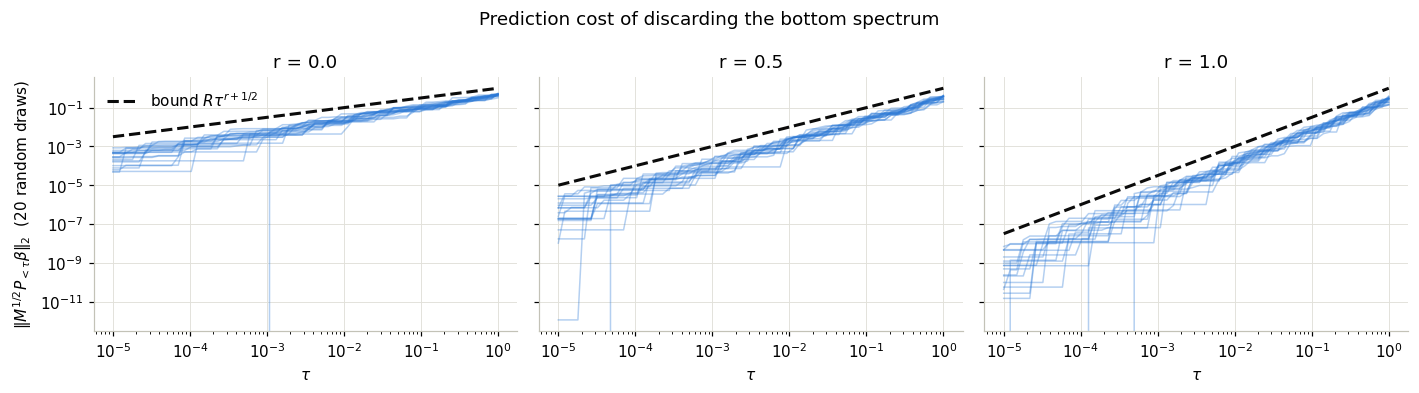

bound violations: 0


In [10]:
m_tb, R_tb = 50, 1.0
taus = np.logspace(-5, 0, 60)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
violations = 0
for ax, r in zip(axes, [0.0, 0.5, 1.0]):
    for trial in range(20):
        Q, _ = np.linalg.qr(rng.normal(size=(m_tb, m_tb)))
        mu = np.sort(rng.uniform(0, 1, m_tb) ** 4)       # many tiny eigenvalues
        M_tb = (Q * mu) @ Q.T
        v = rng.normal(size=m_tb); v *= R_tb / np.linalg.norm(v)
        beta = (Q * mu**r) @ Q.T @ v
        lhs_tb = np.sqrt([energy_below(beta, M_tb, t) for t in taus])
        violations += np.sum(lhs_tb > R_tb * taus ** (r + 0.5) * (1 + 1e-8))
        ax.loglog(taus, lhs_tb, color=COLORS["oracle clean"], alpha=0.35, lw=1)
    ax.loglog(taus, R_tb * taus ** (r + 0.5), "--", color="#0b0b0b", label=r"bound $R\tau^{r+1/2}$")
    ax.set_title(f"r = {r}")
    ax.set_xlabel(r"$\tau$")
axes[0].set_ylabel(r"$\|M^{1/2}P_{<\tau}\beta\|_2$  (20 random draws)")
axes[0].legend()
plt.suptitle("Prediction cost of discarding the bottom spectrum")
plt.tight_layout(); plt.show()
print("bound violations:", violations)
assert violations == 0

### 1c. Two-dimensional example: an additive estimate cannot safely whiten a tiny eigenvalue

$M=\mathrm{diag}(1,\eta)$, $\beta=(1,1)$, $c=M\beta$. We observe $\widehat M=M+E$, $\widehat c=c+e$ with $\|E\|_{op}=\|e\|_2=\delta=10^{-2}$
(adversarial-looking but fixed perturbations). As $\eta$ drops below $\delta$ the eigenvalue $\eta$ is no longer resolved:
whitening ($\widehat M^{-1}\widehat c$) explodes, while ridge ($\lambda=\delta$) and truncation ($\tau=2\delta$) keep the
prediction error at the scale set by the bound in 1b (here $r=0$, $\|v\|=\sqrt2$).

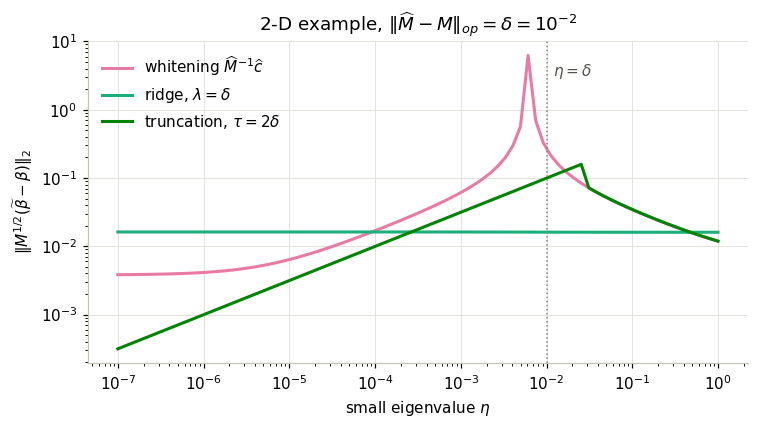

In [11]:
delta = 1e-2
etas = np.logspace(-7, 0, 80)
E = delta * np.array([[0.0, 1.0], [1.0, 0.0]]) / np.sqrt(2) + delta * np.diag([0, -1]) / np.sqrt(2)
E *= delta / np.linalg.norm(E, 2)
e = delta * np.array([0.0, 1.0])
res = {"robust whitening": [], "bound filter": [], "robust truncated": []}
for eta in etas:
    M2 = np.diag([1.0, eta]); beta2 = np.array([1.0, 1.0]); c2 = M2 @ beta2
    Mh, ch = M2 + E, c2 + e
    res["robust whitening"].append(pred_error(np.linalg.solve(Mh, ch), beta2, M2))
    res["bound filter"].append(pred_error(ridge_from_moments(Mh, ch, delta), beta2, M2))
    res["robust truncated"].append(pred_error(truncated_from_moments(Mh, ch, 0.0, 2 * delta), beta2, M2))

labels = {"robust whitening": r"whitening $\widehat M^{-1}\widehat c$",
          "bound filter": r"ridge, $\lambda=\delta$",
          "robust truncated": r"truncation, $\tau=2\delta$"}
fig, ax = plt.subplots(figsize=(7, 4))
for k, v in res.items():
    ax.loglog(etas, v, color=COLORS[k], label=labels[k])
ax.axvline(delta, color="#898781", ls=":", lw=1); ax.text(delta * 1.2, ax.get_ylim()[1] * 0.3, r"$\eta=\delta$", color="#52514e")
ax.set_xlabel(r"small eigenvalue $\eta$"); ax.set_ylabel(r"$\|M^{1/2}(\widetilde\beta-\beta)\|_2$")
ax.set_title(r"2-D example, $\|\widehat M-M\|_{op}=\delta=10^{-2}$")
ax.legend(); plt.tight_layout(); plt.show()

## 2. Clean RFF baseline (Milestone 2)

Data: $X\sim\mathrm{Unif}[-1,1]^d$, $f_\star(x)=\sum_{l=1}^{L}a_l k_\sigma(x,x_l)$ (an RKHS element), $Y=f_\star(X)+\xi$ with
$\xi\sim\mathrm{Unif}[-s,s]$ (bounded responses). We compare exact KRR (sklearn `KernelRidge` with `alpha = n·λ`, matching the
$\frac1n\sum(\cdot)^2+\lambda\|f\|^2$ normalization) with RFF ridge regression, measuring
$\|\widehat f-f_\star\|^2_{L^2(P_X)}$ on a large independent clean sample.

In [12]:
d, sigma, noise = 5, 1.0, 0.3
L_centers = 20
centers = rng.uniform(-1, 1, size=(L_centers, d))
coef = rng.normal(size=L_centers)
coef /= np.max(np.abs(gaussian_kernel(rng.uniform(-1, 1, (5000, d)), centers, sigma) @ coef))   # sup|f*| ~ 1


def f_star(X):
    return gaussian_kernel(X, centers, sigma) @ coef


def sample_xy(n, rng):
    X = rng.uniform(-1, 1, size=(n, d))
    return X, f_star(X) + rng.uniform(-noise, noise, size=n)


X_eval = rng.uniform(-1, 1, size=(20000, d))    # Monte-Carlo proxy for P_X
f_eval = f_star(X_eval)
y_bound_rff = 1.1 * np.max(np.abs(f_eval)) + noise
z_bound_rff = np.sqrt(2.0)


def l2_err(pred):
    return float(np.sqrt(np.mean((pred - f_eval) ** 2)))

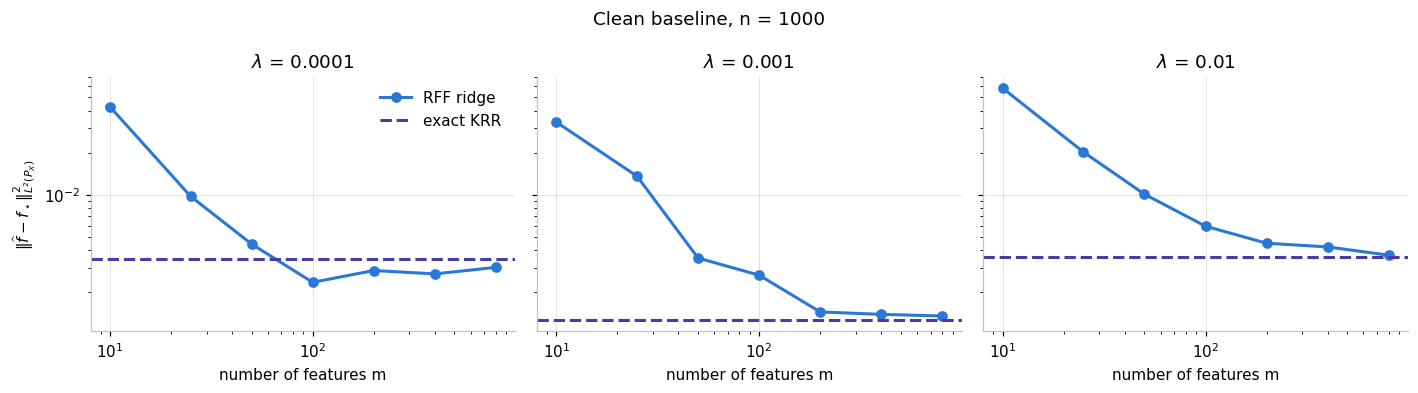

In [13]:
n_base = 1000
m_grid = [10, 25, 50, 100, 200, 400, 800]
lam_grid = [1e-4, 1e-3, 1e-2]
rows = []
for trial in range(3):
    X_tr, y_tr = sample_xy(n_base, rng)
    for lam in lam_grid:
        krr = KernelRidge(alpha=n_base * lam, kernel="rbf", gamma=1 / (2 * sigma**2)).fit(X_tr, y_tr)
        rows.append(dict(trial=trial, lam=lam, m=np.nan, method="exact KRR", err=l2_err(krr.predict(X_eval)) ** 2))
        for m in m_grid:
            W, b = sample_rff(d, m, sigma, rng)
            beta = ridge_from_moments(*empirical_moments(rff(X_tr, W, b), y_tr), lam)
            rows.append(dict(trial=trial, lam=lam, m=m, method="RFF ridge", err=l2_err(rff(X_eval, W, b) @ beta) ** 2))
base = pd.DataFrame(rows)

fig, axes = plt.subplots(1, len(lam_grid), figsize=(13, 3.6), sharey=True)
for ax, lam in zip(axes, lam_grid):
    sub = base[(base.lam == lam) & (base.method == "RFF ridge")].groupby("m").err
    ax.loglog(sub.mean().index, sub.mean().values, "-o", color=COLORS["oracle clean"], label="RFF ridge")
    ax.axhline(base[(base.lam == lam) & (base.method == "exact KRR")].err.mean(), color=COLORS["exact clean KRR"],
               ls="--", label="exact KRR")
    ax.set_title(fr"$\lambda$ = {lam:g}"); ax.set_xlabel("number of features m")
axes[0].set_ylabel(r"$\|\widehat f-f_\star\|^2_{L^2(P_X)}$"); axes[0].legend()
plt.suptitle(f"Clean baseline, n = {n_base}"); plt.tight_layout(); plt.show()

## 3. Synthetic diagonal design (§Experiments, Milestone 3)

Condition on a fixed "feature map" with prescribed spectrum: $Z_j=\sqrt{\mu_j}\,s_j$ with i.i.d. Rademacher $s_j$, so
$M=\mathbb E[ZZ^\top]=\mathrm{diag}(\mu)$ exactly and $\|Z\|_2^2=\sum_j\mu_j=1$ deterministically (bounded like RFFs, $B_z=1$).
$\mu_j\propto j^{-2}$. $Y=\beta^\top Z+\xi$, $\xi\sim\mathrm{Unif}[-s,s]$, so $c=M\beta$ and
$\beta_\lambda=(M+\lambda I)^{-1}M\beta$ are known exactly.

**Target placement.** `top` / `middle` / `bottom`: $\beta$ carries unit prediction energy ($\|M^{1/2}\beta\|=1$) spread over
5 eigendirections at the chosen spectral location. `source`: $\beta=M^rv$ with $r=1/2$, random $v$ scaled to $\|M^{1/2}\beta\|=1$.

In [14]:
m_syn = 50
mu_syn = np.arange(1, m_syn + 1, dtype=float) ** -2.0
mu_syn /= mu_syn.sum()
M_syn = np.diag(mu_syn)
z_bound_syn, noise_syn = 1.0, 0.1


def place_target(location, rng, r=0.5):
    beta = np.zeros(m_syn)
    blocks = {"top": slice(0, 5), "middle": slice(m_syn // 2 - 2, m_syn // 2 + 3), "bottom": slice(m_syn - 5, m_syn)}
    if location == "source":
        beta = mu_syn**r * rng.normal(size=m_syn)
    else:
        blk = blocks[location]
        beta[blk] = rng.choice([-1.0, 1.0], 5) / np.sqrt(mu_syn[blk])
    return beta / np.sqrt(beta @ M_syn @ beta)


def sample_syn(n, beta, rng):
    Z = rng.choice([-1.0, 1.0], size=(n, m_syn)) * np.sqrt(mu_syn)
    return Z, Z @ beta + rng.uniform(-noise_syn, noise_syn, size=n)


def y_bound_syn(beta):
    return np.sum(np.abs(beta) * np.sqrt(mu_syn)) + noise_syn


def run_syn(n, epsilon, lam, location, attack, rng, trial=0, tau=None):
    beta = place_target(location, rng)
    beta_lam = ridge_from_moments(M_syn, M_syn @ beta, lam)
    Z, y = sample_syn(n, beta, rng)
    yb = y_bound_syn(beta)
    Zo, yo, _ = corrupt_pairs(Z, y, epsilon, M_syn, attack, rng, z_bound_syn, yb, lam_attack=lam)
    fits, tau = fit_all(Z, y, Zo, yo, epsilon, lam, z_bound_syn, yb, rng, tau=tau)
    out = []
    for name, (bh, Mh) in fits.items():
        out.append(dict(trial=trial, n=n, epsilon=epsilon, lam=lam, tau=tau, location=location, attack=attack,
                        estimator=name,
                        err_vs_ridge=pred_error(bh, beta_lam, M_syn),     # vs population ridge target
                        err_vs_truth=pred_error(bh, beta, M_syn),         # vs f_star
                        coef_err=float(np.linalg.norm(bh - beta_lam)),
                        op_err=op_error(Mh, M_syn),
                        delta_lam=ridge_relative_error(Mh, M_syn, lam),
                        energy_below=energy_below(beta, M_syn, tau)))
    return out


ROBUST_SET = ["oracle clean", "nonrobust", "bound filter", "GMoM ridge", "robust whitening", "robust truncated"]
N_TRIALS = 5

### 3a. Error vs. $\epsilon$ (source-condition target, low-variance adversary)
Also records $\|\widehat M-M\|_{op}$ and $\Delta_\lambda$ for each moment estimator. $\tau$ follows `tau_rule`.

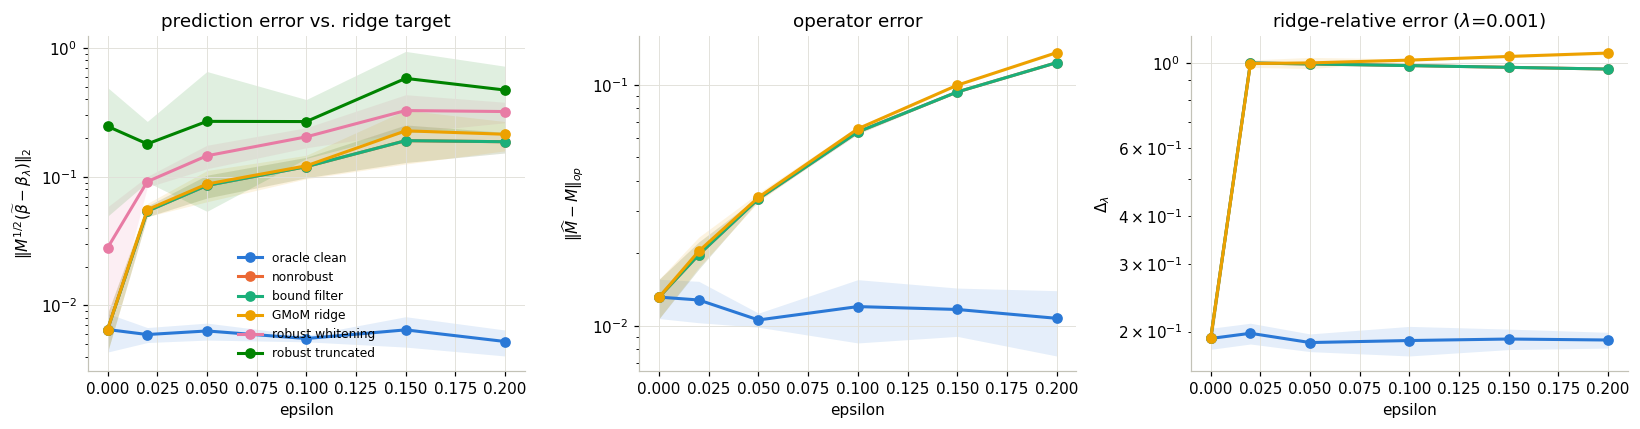

tau_rule by epsilon: {0.0: 0.0697, 0.02: 0.089, 0.05: 0.1179, 0.1: 0.1662, 0.15: 0.2143, 0.2: 0.2624}


err_vs_ridge                                                       \
estimator   GMoM ridge bound filter nonrobust oracle clean robust truncated   
epsilon                                                                       
0.00            0.0065       0.0065    0.0065       0.0065           0.2463   
0.02            0.0554       0.0540    0.0540       0.0059           0.1798   
0.05            0.0878       0.0855    0.0855       0.0063           0.2691   
0.10            0.1215       0.1197    0.1197       0.0055           0.2682   
0.15            0.2273       0.1906    0.1906       0.0065           0.5807   
0.20            0.2137       0.1870    0.1870       0.0052           0.4712   

                               op_err                                      \
estimator robust whitening GMoM ridge bound filter nonrobust oracle clean   
epsilon                                                                     
0.00                0.0280     0.0132       0.0132    0.0132       0.0132   
0.02                0.0916     0.0204       0.0198    0.0198       0.0128   
0.05                0.1454     0.0341       0.0337    0.0337       0.0106   
0.10                0.2040     0.0657       0.0638    0.0638       0.0120   
0.15                0.3266     0.0997       0.0935    0.0935       0.0117   
0.20                0.3208     0.1361       0.1237    0.1237       0.0107   

                                             delta_lam                         \
estimator robust truncated robust whitening GMoM ridge bound filter nonrobust   
epsilon                                                                         
0.00                0.0132           0.0132     0.1919       0.1919    0.1919   
0.02                0.0198           0.0198     0.9945       0.9983    0.9983   
0.05                0.0337           0.0337     0.9988       0.9925    0.9925   
0.10                0.0638           0.0638     1.0156       0.9828    0.9828   
0.15                0.0935           0.0935     1.0381       0.9726    0.9726   
0.20                0.1237           0.1237     1.0595       0.9626    0.9626   

                                                          
estimator oracle clean robust truncated robust whitening  
epsilon                                                   
0.00            0.1919           0.1919           0.1919  
0.02            0.1980           0.9983           0.9983  
0.05            0.1873           0.9925           0.9925  
0.10            0.1896           0.9828           0.9828  
0.15            0.1913           0.9726           0.9726  
0.20            0.1902           0.9626           0.9626

In [15]:
n_syn, lam_syn = 2000, 1e-3
eps_grid = [0.0, 0.02, 0.05, 0.1, 0.15, 0.2]
rows = []
for eps in eps_grid:
    for t in range(N_TRIALS):
        rows += run_syn(n_syn, eps, lam_syn, "source", "low_variance", rng, t)
df_eps = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
plot_lines(axes[0], df_eps, "epsilon", "err_vs_ridge", ROBUST_SET)
axes[0].set_ylabel(r"$\|M^{1/2}(\widetilde\beta-\beta_\lambda)\|_2$"); axes[0].set_title("prediction error vs. ridge target")
moment_set = ["oracle clean", "nonrobust", "bound filter", "GMoM ridge"]
plot_lines(axes[1], df_eps, "epsilon", "op_err", moment_set)
axes[1].set_ylabel(r"$\|\widehat M-M\|_{op}$"); axes[1].set_title("operator error")
plot_lines(axes[2], df_eps, "epsilon", "delta_lam", moment_set)
axes[2].set_ylabel(r"$\Delta_\lambda$"); axes[2].set_title(r"ridge-relative error ($\lambda$=%g)" % lam_syn)
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()
print("tau_rule by epsilon:", df_eps.groupby("epsilon").tau.mean().round(4).to_dict())
df_eps.groupby(["epsilon", "estimator"])[["err_vs_ridge", "op_err", "delta_lam"]].mean().unstack("estimator").round(4)

### 3b. Error vs. truncation threshold $\tau$ for each target placement
Truncation bias is governed by the energy below $\tau$: when the target sits in the `bottom` block, any $\tau$ above
those eigenvalues throws the signal away. The dashed line is $\sqrt{\sum_{\mu_j<\tau}\mu_j\beta_j^2}$.

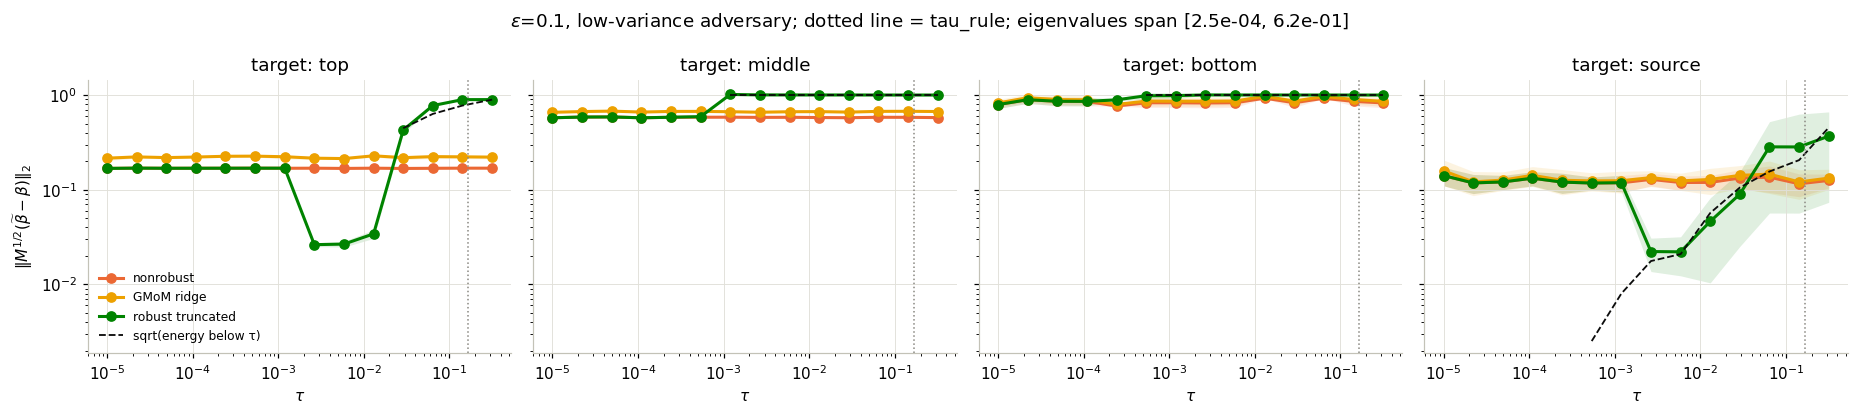

In [16]:
eps_b = 0.1
tau_rule_syn = df_eps[df_eps.epsilon == eps_b].tau.mean()     # where tau_rule lands at this epsilon
tau_grid = np.logspace(-5, -0.5, 14)
rows = []
for loc in ["top", "middle", "bottom", "source"]:
    for tau in tau_grid:
        for t in range(N_TRIALS):
            rows += run_syn(n_syn, eps_b, lam_syn, loc, "low_variance", rng, t, tau=tau)
df_tau = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 4, figsize=(17, 3.8), sharey=True)
for ax, loc in zip(axes, ["top", "middle", "bottom", "source"]):
    sub = df_tau[df_tau.location == loc]
    plot_lines(ax, sub, "tau", "err_vs_truth", ["nonrobust", "GMoM ridge", "robust truncated"], logx=True)
    en = sub[sub.estimator == "robust truncated"].groupby("tau").energy_below.mean()
    en = en[en > 0]
    ax.plot(en.index, np.sqrt(en.values), "--", color="#0b0b0b", lw=1.2, label="sqrt(energy below τ)")
    ax.axvline(tau_rule_syn, color="#898781", ls=":", lw=1)
    ax.set_title(f"target: {loc}"); ax.set_xlabel(r"$\tau$")
axes[0].set_ylabel(r"$\|M^{1/2}(\widetilde\beta-\beta)\|_2$"); axes[0].legend(fontsize=8)
plt.suptitle(fr"$\epsilon$={eps_b}, low-variance adversary; dotted line = tau_rule; eigenvalues span "
             fr"[{mu_syn.min():.1e}, {mu_syn.max():.1e}]")
plt.tight_layout(); plt.show()

### 3c. Error vs. $n$ and vs. $\lambda$
Sampling error should shrink with $n$ while the contamination floor stays; ridge and truncation carry different biases,
so the $(\lambda,\tau)$ interaction is shown separately in 3d.

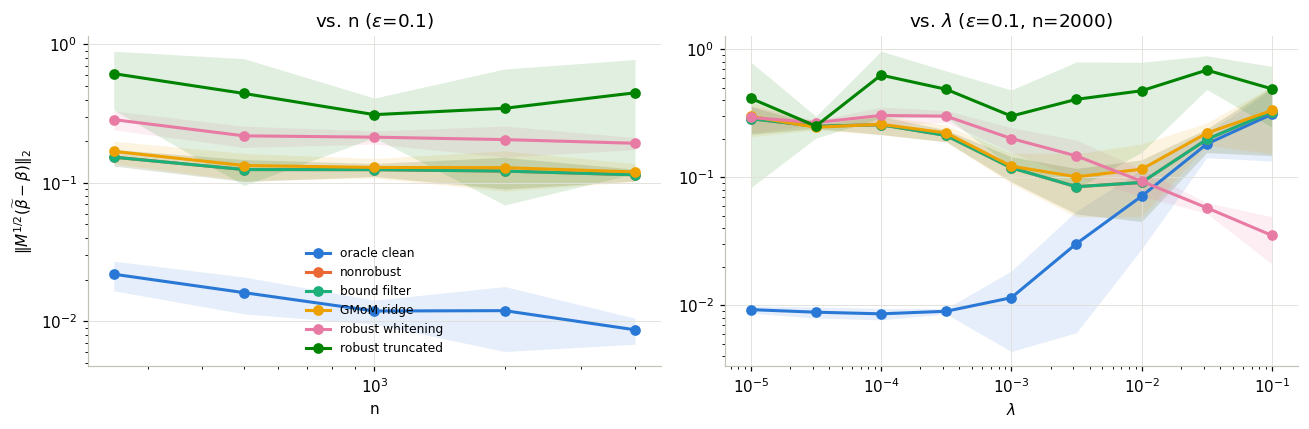

In [17]:
rows = []
for n in [250, 500, 1000, 2000, 4000]:
    for t in range(N_TRIALS):
        rows += run_syn(n, eps_b, lam_syn, "source", "low_variance", rng, t)
df_n = pd.DataFrame(rows)

rows = []
for lam in np.logspace(-5, -1, 9):
    for t in range(N_TRIALS):
        rows += run_syn(n_syn, eps_b, lam, "source", "low_variance", rng, t)
df_lam = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_lines(axes[0], df_n, "n", "err_vs_truth", ROBUST_SET, logx=True)
axes[0].set_ylabel(r"$\|M^{1/2}(\widetilde\beta-\beta)\|_2$"); axes[0].set_title(fr"vs. n ($\epsilon$={eps_b})")
plot_lines(axes[1], df_lam, "lam", "err_vs_truth", ROBUST_SET, logx=True)
axes[1].set_title(fr"vs. $\lambda$ ($\epsilon$={eps_b}, n={n_syn})"); axes[1].set_xlabel(r"$\lambda$")
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

### 3d. $(\lambda,\tau)$ interaction for the truncated estimator
Mean prediction error of the robust truncated estimator vs. $f_\star$ ($\epsilon=0.1$, source target, low-variance adversary).
The circle marks the best cell; the dotted line marks where `tau_rule` lands.

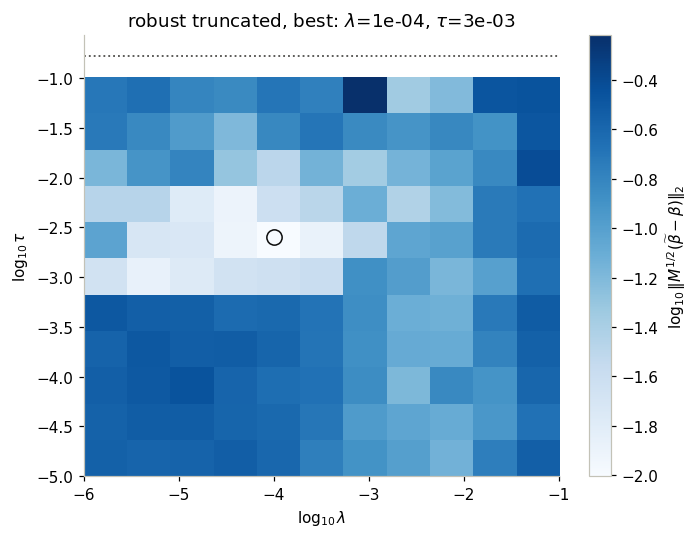

In [18]:
lam_hm = np.logspace(-6, -1, 11)
tau_hm = np.logspace(-5, -1, 11)
H = np.zeros((len(tau_hm), len(lam_hm)))
for i, tau in enumerate(tau_hm):
    for j, lam in enumerate(lam_hm):
        errs = []
        for t in range(3):
            beta = place_target("source", rng)
            Z, y = sample_syn(n_syn, beta, rng)
            yb = y_bound_syn(beta)
            Zo, yo, _ = corrupt_pairs(Z, y, eps_b, M_syn, "low_variance", rng, z_bound_syn, yb, lam_attack=lam)
            Mh, ch = robust_moments(Zo, yo, eps_b, z_bound_syn, yb, ROBUST_METHOD, rng)
            errs.append(pred_error(truncated_from_moments(Mh, ch, lam, tau), beta, M_syn))
        H[i, j] = np.mean(errs)

fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(np.log10(H), origin="lower", cmap="Blues", aspect="auto",
               extent=[np.log10(lam_hm[0]), np.log10(lam_hm[-1]), np.log10(tau_hm[0]), np.log10(tau_hm[-1])])
fig.colorbar(im, ax=ax, label=r"$\log_{10}\|M^{1/2}(\widetilde\beta-\beta)\|_2$")
ax.set_xlabel(r"$\log_{10}\lambda$"); ax.set_ylabel(r"$\log_{10}\tau$"); ax.grid(False)
i_best, j_best = np.unravel_index(np.argmin(H), H.shape)
ax.plot(np.log10(lam_hm[j_best]), np.log10(tau_hm[i_best]), "o", mfc="none", mec="#0b0b0b", ms=10)
ax.axhline(np.log10(tau_rule_syn), color="#52514e", ls=":", lw=1.2)
ax.set_title(fr"robust truncated, best: $\lambda$={lam_hm[j_best]:.0e}, $\tau$={tau_hm[i_best]:.0e}")
plt.tight_layout(); plt.show()

### 3e. Sensitivity to the adversary
Mean prediction error vs. $f_\star$ at $\epsilon=0.1$ for each attack. The low-variance attack is the one
the prospectus singles out: it barely moves $\|\widehat M-M\|_{op}$ yet can move coefficients along $u_{\min}$ a lot.

In [19]:
rows = []
for attack in ATTACKS:
    for t in range(N_TRIALS):
        rows += run_syn(n_syn, eps_b, lam_syn, "source", attack, rng, t)
df_att = pd.DataFrame(rows)
summary = df_att.groupby(["attack", "estimator"]).agg(pred_err=("err_vs_truth", "mean"), coef_err=("coef_err", "mean"),
                                                      op_err=("op_err", "mean"), delta_lam=("delta_lam", "mean"))
summary.unstack("attack").round(4)

pred_err                                       coef_err  \
attack              gross label_flip low_variance top_direction    gross   
estimator                                                                  
GMoM ridge         0.0678     0.1983       0.1403        0.2580   0.6377   
bound filter       0.0153     0.2048       0.1301        0.3054   0.1393   
nonrobust          1.2354     0.2048       0.1301        0.3054   8.0232   
oracle clean       0.0152     0.0162       0.0166        0.0142   0.1322   
robust truncated   0.6342     0.6162       0.3933        0.4475   2.1213   
robust whitening   0.0101     0.2127       0.2183        0.3123   0.4771   

                                                         op_err             \
attack           label_flip low_variance top_direction    gross label_flip   
estimator                                                                    
GMoM ridge           1.3333       8.1062        0.9597   0.0117     0.0122   
bound filter         1.3090       8.1386        0.8106   0.0111     0.0116   
nonrobust            1.3090       8.1386        0.8106  42.6959     0.0116   
oracle clean         0.1299       0.1213        0.1284   0.0110     0.0116   
robust truncated     1.8998       1.5933        1.4300   0.0111     0.0116   
robust whitening     3.2879      13.7671        2.1862   0.0111     0.0116   

                                              delta_lam             \
attack           low_variance top_direction       gross label_flip   
estimator                                                            
GMoM ridge             0.0668        0.0430      0.1992     0.1892   
bound filter           0.0646        0.0401      0.1970     0.1866   
nonrobust              0.0646        0.0401  25566.8947     0.1866   
oracle clean           0.0130        0.0093      0.1874     0.1866   
robust truncated       0.0646        0.0401      0.1970     0.1866   
robust whitening       0.0646        0.0401      0.1970     0.1866   

                                             
attack           low_variance top_direction  
estimator                                    
GMoM ridge             1.0221        0.2488  
bound filter           0.9826        0.2402  
nonrobust              0.9826        0.2402  
oracle clean           0.1916        0.1901  
robust truncated       0.9826        0.2402  
robust whitening       0.9826        0.2402

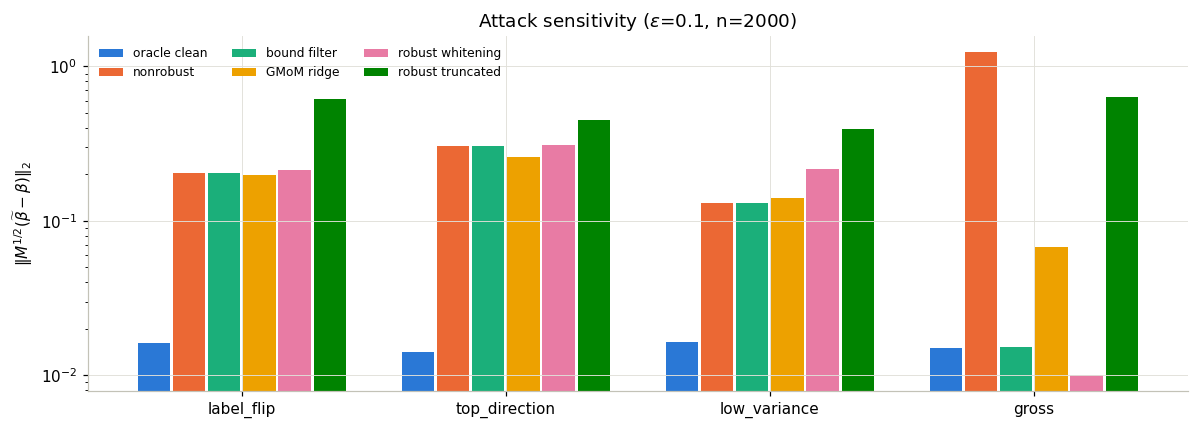

In [20]:
fig, ax = plt.subplots(figsize=(11, 4))
width = 0.8 / len(ROBUST_SET)
x = np.arange(len(ATTACKS))
for k, name in enumerate(ROBUST_SET):
    vals = [df_att[(df_att.attack == a) & (df_att.estimator == name)].err_vs_truth.mean() for a in ATTACKS]
    ax.bar(x + (k - len(ROBUST_SET) / 2 + 0.5) * width, vals, width * 0.92, color=COLORS[name], label=name)
ax.set_xticks(x, ATTACKS); ax.set_yscale("log")
ax.set_ylabel(r"$\|M^{1/2}(\widetilde\beta-\beta)\|_2$"); ax.set_title(fr"Attack sensitivity ($\epsilon$={eps_b}, n={n_syn})")
ax.legend(fontsize=8, ncol=3); plt.tight_layout(); plt.show()

## 4. Full RFF pipeline (§Experiments, §From the finite-dimensional result back to KRR)

Same data as Section 2. Conditional on one feature draw, the population quantities $M=\mathbb E[ZZ^\top]$ and
$c=\mathbb E[Zf_\star(X)]$ are approximated by Monte Carlo on `X_eval` (noise is mean zero and independent, so it drops from $c$).
The population RFF ridge predictor is $f_{m,\lambda}=\beta_\lambda^\top\Phi$. Adversaries act on the feature vectors, which
is stronger than corrupting $x$ (the feature map would force $\|z\|\le\sqrt2$).

Comparators: **exact clean KRR** and **oracle clean RFF ridge** (both fit on the uncorrupted sample), **nonrobust** RFF ridge,
and the robust estimators.

In [21]:
def rff_population(W, b, lam):
    Z_pop = rff(X_eval, W, b)
    M_pop = Z_pop.T @ Z_pop / len(Z_pop)
    c_pop = Z_pop.T @ f_eval / len(Z_pop)
    return Z_pop, M_pop, ridge_from_moments(M_pop, c_pop, lam)


def run_rff(n, m, epsilon, lam, attack, rng, trial=0, tau=None):
    W, b = sample_rff(d, m, sigma, rng)
    Z_pop, M_pop, beta_lam = rff_population(W, b, lam)
    X_tr, y_tr = sample_xy(n, rng)
    Z = rff(X_tr, W, b)
    Zo, yo, _ = corrupt_pairs(Z, y_tr, epsilon, M_pop, attack, rng, z_bound_rff, y_bound_rff, lam_attack=lam)
    fits, tau = fit_all(Z, y_tr, Zo, yo, epsilon, lam, z_bound_rff, y_bound_rff, rng, tau=tau)
    out = []
    for name, (bh, Mh) in fits.items():
        out.append(dict(trial=trial, n=n, m=m, epsilon=epsilon, lam=lam, tau=tau, attack=attack, estimator=name,
                        l2_err=l2_err(Z_pop @ bh),                       # ||f_hat - f*||_{L2(P_X)}
                        err_vs_ridge=pred_error(bh, beta_lam, M_pop),    # ||f_hat - f_{m,lam}||
                        op_err=op_error(Mh, M_pop),
                        delta_lam=ridge_relative_error(Mh, M_pop, lam),
                        energy_below=energy_below(beta_lam, M_pop, tau)))
    krr = KernelRidge(alpha=n * lam, kernel="rbf", gamma=1 / (2 * sigma**2)).fit(X_tr, y_tr)
    out.append(dict(trial=trial, n=n, m=m, epsilon=epsilon, lam=lam, tau=tau, attack=attack, estimator="exact clean KRR",
                    l2_err=l2_err(krr.predict(X_eval))))
    out.append(dict(trial=trial, n=n, m=m, epsilon=epsilon, lam=lam, tau=tau, attack=attack, estimator="population",
                    l2_err=l2_err(Z_pop @ beta_lam), err_vs_ridge=0.0))
    return out


RFF_SET = ["exact clean KRR", "population", "oracle clean", "nonrobust", "bound filter",
           "GMoM ridge", "robust whitening", "robust truncated"]
n_rff, m_rff, lam_rff = 2000, 100, 1e-3

### 4a. Error vs. $\epsilon$ for each adversary

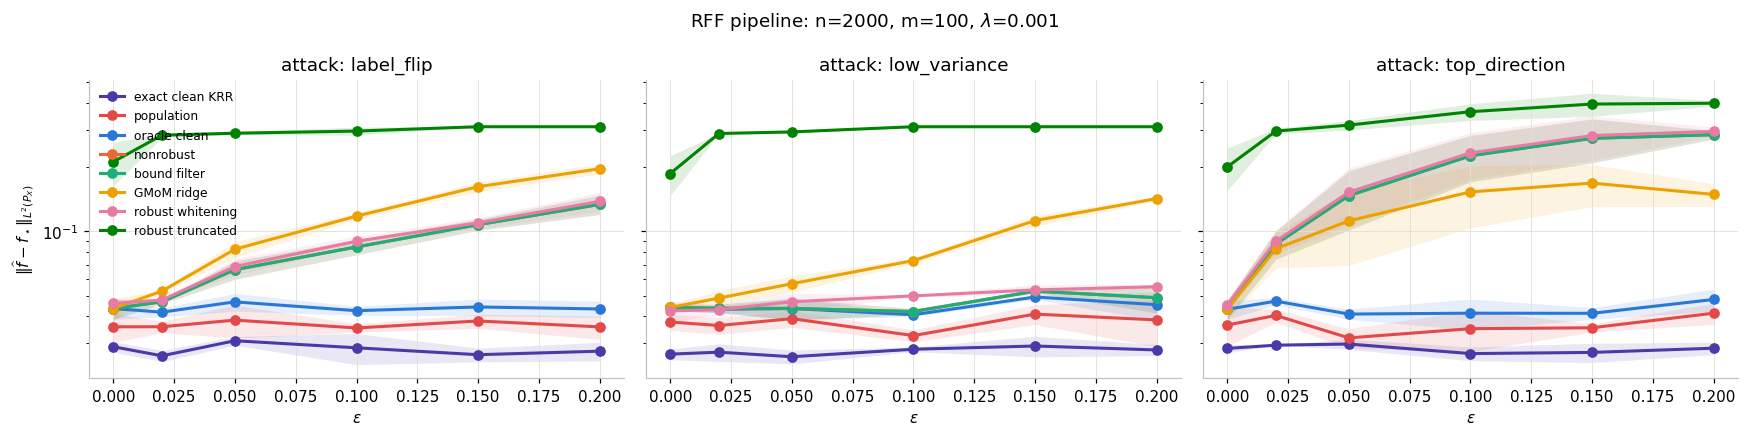

l2_err                                                      \
estimator GMoM ridge bound filter exact clean KRR nonrobust oracle clean   
epsilon                                                                    
0.00          0.0440       0.0440          0.0266    0.0440       0.0440   
0.02          0.0487       0.0437          0.0272    0.0437       0.0432   
0.05          0.0569       0.0436          0.0259    0.0436       0.0435   
0.10          0.0731       0.0422          0.0281    0.0422       0.0407   
0.15          0.1125       0.0525          0.0291    0.0525       0.0493   
0.20          0.1426       0.0489          0.0278    0.0489       0.0454   

                                                       err_vs_ridge  \
estimator population robust truncated robust whitening   GMoM ridge   
epsilon                                                               
0.00          0.0377           0.1869           0.0425       0.0220   
0.02          0.0362           0.2879           0.0430       0.0285   
0.05          0.0390           0.2929           0.0469       0.0367   
0.10          0.0325           0.3098           0.0499       0.0580   
0.15          0.0410           0.3098           0.0533       0.0944   
0.20          0.0385           0.3098           0.0551       0.1283   

                        ...           op_err                   delta_lam  \
estimator bound filter  ... robust truncated robust whitening GMoM ridge   
epsilon                 ...                                                
0.00            0.0220  ...           0.0132           0.0132     0.3033   
0.02            0.0231  ...           0.0138           0.0138     1.0049   
0.05            0.0233  ...           0.0179           0.0179     1.0573   
0.10            0.0259  ...           0.0328           0.0328     1.0930   
0.15            0.0281  ...           0.0431           0.0431     1.1620   
0.20            0.0270  ...           0.0590           0.0590     1.2874   

                                                                          \
estimator bound filter exact clean KRR nonrobust oracle clean population   
epsilon                                                                    
0.00            0.3033             NaN    0.3033       0.3033        NaN   
0.02            1.0001             NaN    1.0001       0.3406        NaN   
0.05            1.0000             NaN    1.0000       0.3506        NaN   
0.10            1.0000             NaN    1.0000       0.3574        NaN   
0.15            0.9999             NaN    0.9999       0.3481        NaN   
0.20            0.9999             NaN    0.9999       0.3787        NaN   

                                             
estimator robust truncated robust whitening  
epsilon                                      
0.00                0.3033           0.3033  
0.02                1.0001           1.0001  
0.05                1.0000           1.0000  
0.10                1.0000           1.0000  
0.15                0.9999           0.9999  
0.20                0.9999           0.9999  

[6 rows x 32 columns]

In [22]:
rows = []
for attack in ["label_flip", "low_variance", "top_direction"]:
    for eps in eps_grid:
        for t in range(3):
            rows += run_rff(n_rff, m_rff, eps, lam_rff, attack, rng, t)
df_rff = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, attack in zip(axes, ["label_flip", "low_variance", "top_direction"]):
    plot_lines(ax, df_rff[df_rff.attack == attack], "epsilon", "l2_err", RFF_SET)
    ax.set_title(f"attack: {attack}"); ax.set_xlabel(r"$\epsilon$")
axes[0].set_ylabel(r"$\|\widehat f-f_\star\|_{L^2(P_X)}$"); axes[0].legend(fontsize=8)
plt.suptitle(fr"RFF pipeline: n={n_rff}, m={m_rff}, $\lambda$={lam_rff}"); plt.tight_layout(); plt.show()

(df_rff[df_rff.attack == "low_variance"]
 .groupby(["epsilon", "estimator"])[["l2_err", "err_vs_ridge", "op_err", "delta_lam"]].mean()
 .unstack("estimator").round(4))

### 4b. Error vs. number of features $m$ ($\epsilon=0.1$)

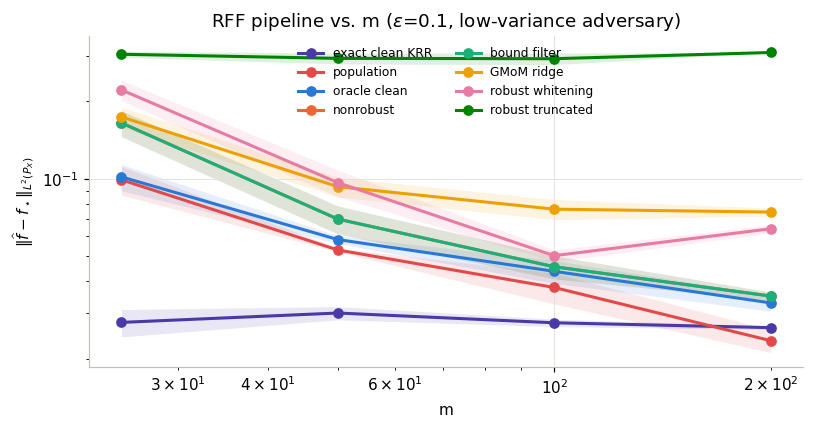

In [23]:
rows = []
for m in [25, 50, 100, 200]:
    for t in range(3):
        rows += run_rff(n_rff, m, 0.1, lam_rff, "low_variance", rng, t)
df_m = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(7.5, 4))
plot_lines(ax, df_m, "m", "l2_err", RFF_SET, logx=True)
ax.set_ylabel(r"$\|\widehat f-f_\star\|_{L^2(P_X)}$"); ax.set_title(r"RFF pipeline vs. m ($\epsilon$=0.1, low-variance adversary)")
ax.legend(fontsize=8, ncol=2); plt.tight_layout(); plt.show()

### 4c. Truncation threshold in the RFF setting ($\epsilon=0.1$)
Error of the robust truncated estimator as $\tau$ varies, next to the eigenvalues of $M$ (ticks along the top) and the value
chosen by `tau_rule` (dotted). This shows how conservative the worst-case route-(c) scale is for this feature distribution.

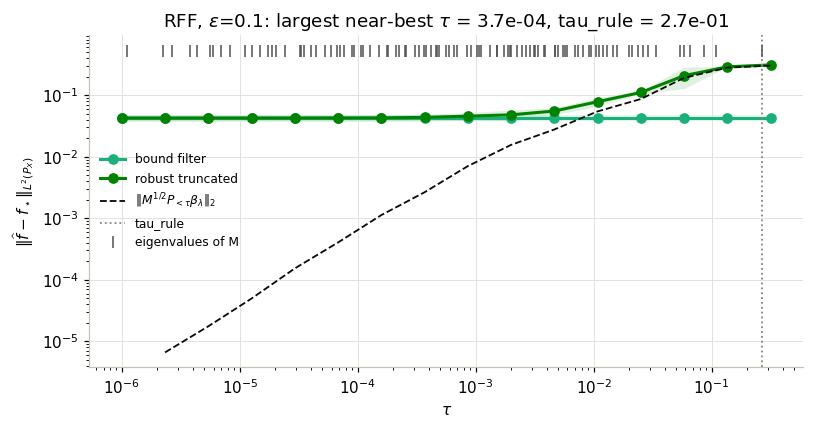

In [24]:
tau_grid_rff = np.logspace(-6, -0.5, 16)
rows = []
for t in range(3):
    W, b = sample_rff(d, m_rff, sigma, rng)
    Z_pop, M_pop, beta_lam = rff_population(W, b, lam_rff)
    X_tr, y_tr = sample_xy(n_rff, rng)
    Zo, yo, _ = corrupt_pairs(rff(X_tr, W, b), y_tr, 0.1, M_pop, "low_variance", rng, z_bound_rff, y_bound_rff,
                              lam_attack=lam_rff)
    Mh, ch = robust_moments(Zo, yo, 0.1, z_bound_rff, y_bound_rff, ROBUST_METHOD, rng)
    rule = tau_rule(Mh, 0.1, n_rff, z_bound_rff)
    ridge_err = l2_err(Z_pop @ ridge_from_moments(Mh, ch, lam_rff))
    for tau in tau_grid_rff:
        bh = truncated_from_moments(Mh, ch, lam_rff, tau)
        rows.append(dict(trial=t, tau=tau, estimator="robust truncated", l2_err=l2_err(Z_pop @ bh), rule=rule,
                         energy_below=energy_below(beta_lam, M_pop, tau)))
        rows.append(dict(trial=t, tau=tau, estimator="bound filter", l2_err=ridge_err, rule=rule))
df_tau_rff = pd.DataFrame(rows)
err_by_tau = df_tau_rff[df_tau_rff.estimator == "robust truncated"].groupby("tau").l2_err.mean()
tau_best_rff = err_by_tau[err_by_tau <= 1.05 * err_by_tau.min()].index.max()   # most aggressive tau within 5% of best

fig, ax = plt.subplots(figsize=(7.5, 4))
plot_lines(ax, df_tau_rff, "tau", "l2_err", ["bound filter", "robust truncated"], logx=True)
en = df_tau_rff.dropna(subset=["energy_below"]).groupby("tau").energy_below.mean()
en = en[en > 0]
ax.plot(en.index, np.sqrt(en.values), "--", color="#0b0b0b", lw=1.2, label=r"$\|M^{1/2}P_{<\tau}\beta_\lambda\|_2$")
ax.axvline(df_tau_rff.rule.mean(), color="#898781", ls=":", lw=1.2, label="tau_rule")
mu_pop = np.linalg.eigvalsh(M_pop)
ax.plot(mu_pop[mu_pop > tau_grid_rff[0]], np.full(np.sum(mu_pop > tau_grid_rff[0]), ax.get_ylim()[1]), "|",
        color="#52514e", ms=8, label="eigenvalues of M")
ax.set_xlabel(r"$\tau$"); ax.set_ylabel(r"$\|\widehat f-f_\star\|_{L^2(P_X)}$")
ax.set_title(fr"RFF, $\epsilon$=0.1: largest near-best $\tau$ = {tau_best_rff:.1e}, tau_rule = {df_tau_rff.rule.mean():.1e}")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

### 4d. Error decomposition (eq. decomp)
$\|\widehat f_{\rm rob}-f_\star\|\le\underbrace{\|\widehat f_{\rm rob}-f_{m,\lambda}\|}_{\text{robust estimation}}
+\underbrace{\|f_{m,\lambda}-f_\lambda\|}_{\text{RF approximation}}+\underbrace{\|f_\lambda-f_\star\|}_{\text{ridge bias / stat.}}$

All norms are $L^2(P_X)$ on `X_eval`. $f_{m,\lambda}$ is the population RFF ridge predictor (for this feature draw).
The exact-kernel population comparator $f_\lambda$ is not available in closed form; we use exact KRR fit on a large
independent clean sample ($N=4000$) as its proxy, so the last term also contains a small amount of sampling error.

         robust_estimation  rf_approximation  ridge_bias   total  sum_of_terms
epsilon                                                                       
0.00                0.0251            0.0368      0.0197  0.0441        0.0816
0.05                0.0240            0.0333      0.0197  0.0424        0.0769
0.10                0.0268            0.0372      0.0197  0.0492        0.0837
0.20                0.0292            0.0342      0.0197  0.0469        0.0831


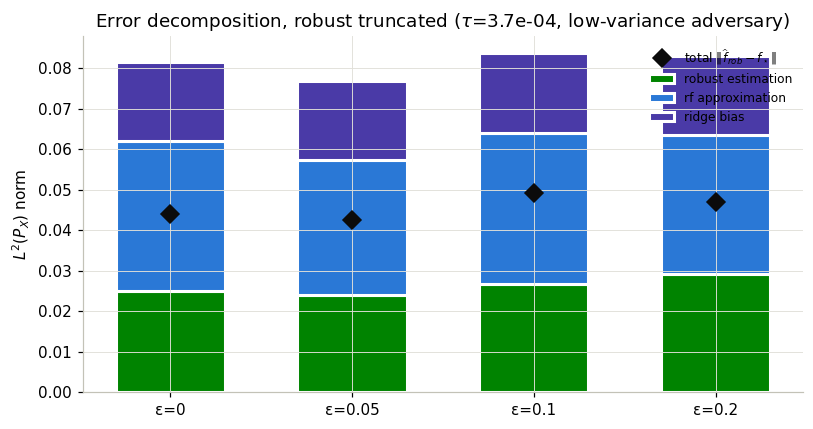

In [25]:
N_proxy = 4000
X_px, y_px = sample_xy(N_proxy, rng)
f_lam = KernelRidge(alpha=N_proxy * lam_rff, kernel="rbf", gamma=1 / (2 * sigma**2)).fit(X_px, y_px).predict(X_eval)

tau_4d = tau_best_rff     # from 4c; replace to test other thresholds
rows = []
for eps in [0.0, 0.05, 0.1, 0.2]:
    for t in range(3):
        W, b = sample_rff(d, m_rff, sigma, rng)
        Z_pop, M_pop, beta_lam = rff_population(W, b, lam_rff)
        X_tr, y_tr = sample_xy(n_rff, rng)
        Zo, yo, _ = corrupt_pairs(rff(X_tr, W, b), y_tr, eps, M_pop, "low_variance", rng, z_bound_rff, y_bound_rff,
                                  lam_attack=lam_rff)
        Mh, ch = robust_moments(Zo, yo, eps, z_bound_rff, y_bound_rff, ROBUST_METHOD, rng)
        f_rob = Z_pop @ truncated_from_moments(Mh, ch, lam_rff, tau_4d)
        f_mlam = Z_pop @ beta_lam
        rms = lambda g: float(np.sqrt(np.mean(g**2)))
        rows.append(dict(epsilon=eps, trial=t, robust_estimation=rms(f_rob - f_mlam), rf_approximation=rms(f_mlam - f_lam),
                         ridge_bias=rms(f_lam - f_eval), total=rms(f_rob - f_eval)))
dec = pd.DataFrame(rows).groupby("epsilon").mean().drop(columns="trial")
dec["sum_of_terms"] = dec[["robust_estimation", "rf_approximation", "ridge_bias"]].sum(axis=1)
display(dec.round(4)) if "display" in globals() else print(dec.round(4))

fig, ax = plt.subplots(figsize=(7.5, 4))
terms = [("robust_estimation", COLORS["robust truncated"]), ("rf_approximation", COLORS["oracle clean"]),
         ("ridge_bias", COLORS["exact clean KRR"])]
bottom = np.zeros(len(dec))
xs = np.arange(len(dec))
for col, color in terms:
    ax.bar(xs, dec[col], 0.6, bottom=bottom, color=color, label=col.replace("_", " "), edgecolor="white", linewidth=2)
    bottom += dec[col].values
ax.plot(xs, dec["total"], "D", color="#0b0b0b", ms=8, label=r"total $\|\widehat f_{rob}-f_\star\|$")
ax.set_xticks(xs, [f"ε={e:g}" for e in dec.index])
ax.set_ylabel(r"$L^2(P_X)$ norm"); ax.set_title(fr"Error decomposition, robust truncated ($\tau$={tau_4d:.1e}, low-variance adversary)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()